# 01 - SQL data quality and business analysis

**Business context.** Kasa Telecom (synthetic) sells prepaid bundles, postpaid plans and home fibre in Ghana. Management wants to know how fast customers are leaving, where, and what signals precede it.

This notebook runs the same SQL the platform runs: data-quality checks on the raw tables, then business questions on the cleaned views. All SQL lives in `insightforge/sql/` and is portable across MySQL 8 / MariaDB and SQLite.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("STORAGE_DIR", str(ROOT / "storage" / "notebooks"))  # isolated from the app database
os.environ.setdefault("LOG_LEVEL", "WARNING")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

from insightforge.db import init_db, run_query, load_named_queries, load_sql
from insightforge.auth import sign_up, login, AuthError
from insightforge.ingest import load_synthetic, list_datasets, get_dataset
init_db()
try:
    user = login("notebook@kasatelecom.example", "Notebook#2026")
except AuthError:
    user = sign_up("Kasa Telecom", "Telecommunications", "Christokin Christopherson",
                   "notebook@kasatelecom.example", "Notebook#2026")
WS = user.workspace_id
ds = list_datasets(WS)
DATASET_ID = int(ds.iloc[0]["id"]) if not ds.empty else load_synthetic(WS, n_customers=8000, seed=42)
dataset = get_dataset(DATASET_ID, WS)
print(f"workspace {WS}, dataset {DATASET_ID}: {dataset['name']}")

workspace 1, dataset 1: Kasa Telecom synthetic (seed 42, 8,000 customers)


## 1. Relational schema

Raw (bronze) tables hold the operational data exactly as received, imperfections included. Cleaned (silver) views de-duplicate, standardise and drop personal data. See `docs/schema.md` for the full ERD.

In [2]:
from insightforge.db import table_counts
pd.DataFrame(table_counts(WS).items(), columns=["table", "rows"])

,table,rows
0,plans,8
1,customers,8120
2,subscriptions,8000
3,monthly_usage,142238
4,payments,141815
5,support_tickets,30079


In [3]:
run_query("SELECT * FROM customers WHERE workspace_id = :ws LIMIT 5", {"ws": WS})  # raw: note PII and messy region labels

,row_id,workspace_id,customer_id,full_name,phone,email,gender,date_of_birth,region,city,segment,acquisition_channel,signup_date
0,7452,1,C07452,Fatima Kpodo,+233200005181,fatima.kpodo229@example.com,Female,2007-01-27,Greater Accra,Tema,SME,Agent,2025-04-16
1,4495,1,C04495,Rahinatu Appiah,+233200015352,rahinatu.appiah850@example.com,Male,1996-07-25,Central,Cape Coast,Consumer,Agent,2026-04-16
2,7291,1,C07291,Gifty Abubakar,+233200017999,gifty.abubakar982@example.com,Male,1989-03-01,Greater Accra,Kasoa,Consumer,Retail Shop,2026-08-25
3,4975,1,C04975,Vida Antwi,+233200023960,vida.antwi144@example.com,Male,1999-09-20,Ashanti,Kumasi,Consumer,Referral,2025-08-07
4,2301,1,C02301,Linda Appiah,+233200029370,linda.appiah181@example.com,Male,1991-09-02,Western,Takoradi,Consumer,Retail Shop,2024-10-17


In [4]:
run_query("SELECT * FROM v_customers_clean WHERE workspace_id = :ws LIMIT 5", {"ws": WS})  # clean: no PII, canonical regions

,workspace_id,customer_id,gender,date_of_birth,segment,acquisition_channel,signup_date,region
0,1,C07452,Female,2007-01-27,SME,Agent,2025-04-16,Greater Accra
1,1,C04495,Male,1996-07-25,Consumer,Agent,2026-04-16,Central
2,1,C07291,Male,1989-03-01,Consumer,Retail Shop,2026-08-25,Greater Accra
3,1,C04975,Male,1999-09-20,Consumer,Referral,2025-08-07,Ashanti
4,1,C02301,Male,1991-09-02,Consumer,Retail Shop,2024-10-17,Western


## 2. Data-quality checks

Each check is a named SQL query in `sql/dq_checks.sql` returning the issue count and the rows checked.

In [5]:
from insightforge.analysis import run_dq_checks
dq = run_dq_checks(WS)
dq.drop(columns=["sql"])

,check,description,table,severity,issues,rows_checked,issue_pct,handling
0,customers_missing_region,Customers with no region recorded,customers,medium,266,8120,3.28,"Kept; region treated as ""Unknown"" category in ..."
1,customers_missing_dob,Customers with no date of birth,customers,low,281,8120,3.46,Age imputed with the median inside the ML pipe...
2,customers_nonstandard_region,Region labels that do not match the reference ...,customers,medium,770,8120,9.48,Standardised in v_customers_clean (e.g. 'Gt. A...
3,customers_duplicate_phone,Duplicate customer registrations (same phone n...,customers,high,120,8120,1.48,De-duplicated in v_customers_clean - earliest ...
4,subscriptions_end_before_start,Subscriptions whose end date is before the sta...,subscriptions,high,15,8000,0.19,Quarantined (excluded) in v_subscriptions_clea...
5,subscriptions_status_mismatch,Subscriptions whose status disagrees with the ...,subscriptions,high,22,8000,0.28,Status re-derived from end_date in v_subscript...
6,usage_duplicate_months,Duplicate usage records for the same subscript...,monthly_usage,medium,1129,142238,0.79,De-duplicated in v_usage_clean (first record k...
7,usage_negative_or_missing,Usage readings that are negative or missing,monthly_usage,medium,1090,142238,0.77,Negative values set to NULL; missing values im...
8,usage_implausible,Usage readings above 5x the plan allowance (me...,monthly_usage,low,131,142238,0.09,Set to NULL in v_usage_clean.
9,payments_double_posted,Bills posted more than once for the same subsc...,payments,high,706,141815,0.50,De-duplicated in v_payments_clean - otherwise ...


In [6]:
print(load_named_queries("dq_checks.sql")["customers_duplicate_phone"].sql)

SELECT COALESCE(SUM(cnt - 1), 0) AS issue_count,
       (SELECT COUNT(*) FROM customers WHERE workspace_id = :ws) AS total_rows
FROM (
    SELECT phone, COUNT(*) AS cnt
    FROM customers
    WHERE workspace_id = :ws AND phone IS NOT NULL
    GROUP BY phone
    HAVING COUNT(*) > 1
) d


**Reading the checks.** The high-severity issues are the ones that would change business numbers: duplicate registrations and double-posted bills overstate customers and revenue, and subscriptions whose status or dates disagree would misstate churn - the outcome we model. Each is handled in the silver views (`ROW_NUMBER()` de-duplication, status re-derived from `end_date`, quarantine of impossible dates). Region spelling variants (e.g. 'Gt. Accra', 'kumasi') are mapped to canonical regions; out-of-range values become NULL and are imputed inside the ML pipeline.

## 3. Business questions

Parameters (snapshot dates, windows) are computed in Python and bound into the SQL, so the same queries work for any as-of date.

In [7]:
from insightforge.analysis import analysis_params, run_analysis, to_date
AS_OF = to_date(dataset["as_of_date"])
params = analysis_params(WS, AS_OF)
res = run_analysis(WS, AS_OF)
params

{'ws': 1,
 'as_of': '2026-09-30',
 'snapshot': '2026-06-30',
 'horizon_end': '2026-09-28',
 'm3_start': '2026-04-01',
 'm6_start': '2026-01-01',
 'd90_snapshot': '2026-04-01',
 't3': '2026-03-31',
 't12': '2025-06-30',
 't24': '2024-06-30',
 'd90_start': '2026-07-02',
 'd180_start': '2026-04-03',
 'd365_start': '2025-09-30',
 'trend_start': '2025-04-01',
 'month_after_as_of': '2026-10-01'}

### 3.1 Headline KPIs (CTE + conditional aggregation)

In [8]:
print(res["kpi_summary"].sql)
res["kpi_summary"].data

WITH subs AS (
    SELECT s.start_date, s.end_date, s.cancel_reason, p.monthly_fee
    FROM v_subscriptions_clean s
    JOIN plans p ON p.workspace_id = s.workspace_id AND p.plan_id = s.plan_id
    WHERE s.workspace_id = :ws
),
k AS (
    SELECT
        SUM(CASE WHEN start_date <= :as_of AND (end_date IS NULL OR end_date > :as_of) THEN 1 ELSE 0 END) AS active_customers,
        SUM(CASE WHEN start_date <= :as_of AND (end_date IS NULL OR end_date > :as_of) THEN monthly_fee ELSE 0 END) AS mrr_ghs,
        SUM(CASE WHEN start_date <= :d90_start AND (end_date IS NULL OR end_date > :d90_start) THEN 1 ELSE 0 END) AS active_90d_ago,
        SUM(CASE WHEN end_date > :d90_start AND end_date <= :as_of THEN 1 ELSE 0 END) AS churned_last_90d,
        SUM(CASE WHEN end_date > :d90_start AND end_date <= :as_of AND cancel_reason = 'Non-payment' THEN 1 ELSE 0 END) AS involuntary_last_90d,
        SUM(CASE WHEN start_date > :d90_start AND start_date <= :as_of THEN 1 ELSE 0 END) AS new_last_90d
    FROM

,active_customers,mrr_ghs,arpu_ghs,churned_last_90d,involuntary_last_90d,new_last_90d,churn_rate_90d_pct,net_adds_90d
0,4173,721925.0,173.0,295,26,384,7.22,89


### 3.2 Monthly churn trend (CTE, LEAD for month boundaries, LAG for month-on-month change, moving-average window)

In [9]:
print(res["monthly_churn_trend"].sql)
trend = res["monthly_churn_trend"].data
trend

WITH months AS (
    SELECT DISTINCT usage_month AS m
    FROM monthly_usage
    WHERE workspace_id = :ws AND usage_month >= :trend_start
),
bounds AS (
    SELECT m, COALESCE(LEAD(m) OVER (ORDER BY m), :month_after_as_of) AS m_next
    FROM months
),
agg AS (
    SELECT
        b.m AS month_start,
        SUM(CASE WHEN s.start_date < b.m AND (s.end_date IS NULL OR s.end_date >= b.m) THEN 1 ELSE 0 END) AS active_at_start,
        SUM(CASE WHEN s.start_date >= b.m AND s.start_date < b.m_next THEN 1 ELSE 0 END) AS new_customers,
        SUM(CASE WHEN s.end_date >= b.m AND s.end_date < b.m_next THEN 1 ELSE 0 END) AS churned,
        SUM(CASE WHEN s.end_date >= b.m AND s.end_date < b.m_next AND s.cancel_reason = 'Non-payment' THEN 1 ELSE 0 END) AS churned_involuntary
    FROM bounds b
    CROSS JOIN v_subscriptions_clean s
    WHERE s.workspace_id = :ws
    GROUP BY b.m
)
SELECT
    month_start,
    active_at_start,
    new_customers,
    churned,
    churned_involuntary,
    ROUND(100.0 *

,month_start,active_at_start,new_customers,churned,churned_involuntary,churn_rate_pct,mom_change_pp,churn_rate_3m_avg
0,2025-04-01,3201,148,102,14,3.19,NaN,3.19
1,2025-05-01,3247,149,60,8,1.85,-1.34,2.52
2,2025-06-01,3336,171,86,11,2.58,0.73,2.54
3,2025-07-01,3421,163,93,16,2.72,0.14,2.38
4,2025-08-01,3491,141,69,11,1.98,-0.74,2.42
5,2025-09-01,3563,151,86,16,2.41,0.44,2.37
6,2025-10-01,3628,165,136,19,3.75,1.33,2.71
7,2025-11-01,3657,178,104,11,2.84,-0.90,3.00
8,2025-12-01,3731,169,137,15,3.67,0.83,3.42
9,2026-01-01,3763,171,114,8,3.03,-0.64,3.18


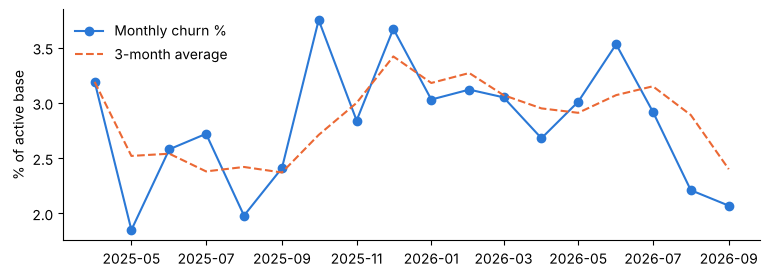

In [10]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(trend.month_start, trend.churn_rate_pct, marker="o", color="#2a78d6", label="Monthly churn %")
ax.plot(trend.month_start, trend.churn_rate_3m_avg, ls="--", color="#eb6834", label="3-month average")
ax.set_ylabel("% of active base"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 3.3 Is the change regional?

In [11]:
reg = res["monthly_churn_by_region"].data.copy()
reg["group"] = reg.region.where(reg.region == "Greater Accra", "Rest of country")
g = reg.groupby(["month_start", "group"])[["churned", "active_at_start"]].sum()
(100 * g.churned / g.active_at_start).unstack().round(2).tail(12)

group,Greater Accra,Rest of country
month_start,,
2025-10-01,4.52,3.34
2025-11-01,2.87,2.83
2025-12-01,4.02,3.49
2026-01-01,2.99,3.05
2026-02-01,2.24,3.56
2026-03-01,2.94,3.11
2026-04-01,4.33,1.82
2026-05-01,4.22,2.40
2026-06-01,4.88,2.86


**What it means.** Two events stand out. Churn jumped in **October 2025** when prepaid bundle prices rose 15% (the effect fades over the following months). Then from **April to July 2026** Greater Accra churn roughly doubled while the rest of the country stayed flat - the signature of a local competitor offer; 'Moved to competitor' is a top-four cancellation reason. Both are actionable: one is a pricing decision, the other needs a regional counter-offer.

### 3.4 Segment drivers (90-day outcome window after the last fully observed snapshot)

In [12]:
for name in ["churn_by_contract_plan", "churn_by_tenure", "payment_behaviour_vs_churn",
             "support_experience_vs_churn", "usage_decline_early_warning"]:
    q = res[name]
    print(f"\n== {q.title}  -  {q.meta.get('question')}")
    display(q.data)


== 90-day churn by contract and plan type  -  Which contract and product combinations lose the most customers?


,contract_type,plan_type,customers,churned_90d,churn_rate_90d_pct,mrr_ghs
0,Month-to-month,Prepaid,1514,164,10.83,103728.0
1,Month-to-month,Postpaid,402,34,8.46,75243.0
2,12-month,Prepaid,262,21,8.02,17969.0
3,Month-to-month,Fibre,129,9,6.98,56840.0
4,12-month,Postpaid,823,27,3.28,147929.0
5,24-month,Fibre,196,6,3.06,85190.0
6,24-month,Postpaid,478,14,2.93,85331.0
7,12-month,Fibre,272,4,1.47,122230.0



== 90-day churn by tenure band  -  Are new customers more likely to leave than established ones?


,tenure_band,customers,churned_90d,churn_rate_90d_pct
0,1. 0-3 months,501,58,11.58
1,2. 4-12 months,1075,98,9.12
2,3. 13-24 months,915,47,5.14
3,4. 24+ months,1585,76,4.79



== Payment behaviour (last 6 months) vs 90-day churn  -  Do late or missed payments signal that a customer is about to leave?


,payment_profile,customers,churned_90d,churn_rate_90d_pct
0,0. Always on time,2365,147,6.22
1,1. Paid late once,790,63,7.97
2,2. Paid late 2+ times,305,20,6.56
3,3. Missed at least one bill,616,49,7.95



== Support experience (90 days before snapshot) vs 90-day churn  -  Do customers who struggle with support leave more often?


,support_profile,customers,churned_90d,churn_rate_90d_pct
0,0. No tickets,2265,128,5.65
1,1. One ticket,1245,103,8.27
2,2. 2+ tickets,476,39,8.19
3,3. Gave a CSAT of 1-2,90,9,10.00



== Usage trend (last 3 vs prior 3 months) vs 90-day churn  -  Does falling data usage give an early warning before customers leave?


,usage_trend,customers,churned_90d,churn_rate_90d_pct
0,1. Down 40%+,15,9,60.00
1,2. Down 10-40%,867,75,8.65
2,3. Stable (+/-10%),1370,61,4.45
3,4. Up 10%+,923,37,4.01


In [13]:
print(res["usage_decline_early_warning"].sql)

WITH active AS (
    SELECT s.subscription_id,
           CASE WHEN s.end_date > :snapshot AND s.end_date <= :horizon_end THEN 1 ELSE 0 END AS churned
    FROM v_subscriptions_clean s
    WHERE s.workspace_id = :ws AND s.start_date <= :m6_start
      AND (s.end_date IS NULL OR s.end_date > :snapshot)
),
u AS (
    SELECT u.subscription_id,
           AVG(CASE WHEN u.usage_month >= :m3_start THEN u.data_gb_used END) AS recent,
           AVG(CASE WHEN u.usage_month < :m3_start THEN u.data_gb_used END) AS prior
    FROM v_usage_clean u
    WHERE u.workspace_id = :ws AND u.usage_month >= :m6_start AND u.usage_month <= :snapshot
    GROUP BY u.subscription_id
),
banded AS (
    SELECT a.churned,
           CASE
               WHEN u.prior IS NULL OR u.prior = 0 OR u.recent IS NULL THEN '9. Not enough history'
               WHEN u.recent / u.prior < 0.6 THEN '1. Down 40%+'
               WHEN u.recent / u.prior < 0.9 THEN '2. Down 10-40%'
               WHEN u.recent / u.prior <= 1.1 THEN 

**What it means.**

* **Contract is the biggest structural lever:** month-to-month prepaid customers leave at roughly 7x the rate of 12-month fibre customers.
* **New customers are fragile:** churn in the first year is about double that of customers with 2+ years' tenure, so onboarding matters.
* **Falling usage is the clearest early warning:** customers whose data use fell 10-40% churn at about twice the rate of stable users (the small 'down 40%+' group is extreme but tiny - treat with care).
* **Poor support experience** (tickets, and especially low CSAT) is associated with higher churn.
* **Payment behaviour is a weaker signal** for voluntary churn than expected; missed payments mainly drive *involuntary* churn (the separate payment-delinquency use case models that directly).

These are associations; the model in notebook 02 combines them and the retention test proposed in the report would establish cause.

### 3.5 Why customers say they leave (window function for share of total)

In [14]:
res["cancel_reasons"].data

,cancel_reason,cancellations,lost_mrr_ghs,share_pct
0,Price,350,36282.0,25.1
1,Not captured,249,26650.0,17.9
2,Poor network,192,20165.0,13.8
3,Moved to competitor,172,19919.0,12.3
4,Poor customer service,170,18455.0,12.2
5,Non-payment,140,24088.0,10.1
6,Relocation,72,8164.0,5.2
7,Other,48,5372.0,3.4


In [15]:
res["support_by_category"].data

,category,tickets,avg_resolution_hours,avg_csat,no_survey_pct
0,Network,2352,35.8,3.83,31.3
1,Data Speed,1078,34.7,3.88,29.2
2,Device,341,11.7,4.12,29.9
3,Account,360,11.2,4.14,29.4
4,Billing,1081,11.2,4.16,31.7


Network and data-speed tickets take about three times as long to resolve and score lowest on CSAT - consistent with 'Poor network' being a leading cancellation reason.